# EE6423 — Ước lượng độ sáng thật của điểm ảnh từ video camera cố định khi có nhiễu cảm biến, nhấp nháy đèn lưới điện

**Bài tập lớn M4 | Xử lý tín hiệu ngẫu nhiên**

Notebook độc lập, dữ liệu hoàn toàn mô phỏng. Mỗi chương gồm cơ sở lý thuyết, mã triển khai và kết quả. Đọc từ trên xuống hoặc chạy **Runtime → Restart session and run all** trên Colab (CPU). Không cần tải dữ liệu, mount Drive hoặc cài bộ lọc bên ngoài.

# Chương 0. Khởi tạo

Dùng NumPy, SciPy, Matplotlib và Pandas. Toàn bộ tham số mô phỏng tập trung trong `config`; không dùng tham số thật của tập kiểm thử cho bộ lọc. Các seed hiệu chuẩn (11), đánh giá hiệu chuẩn (500–529), validation (100–109), kiểm thử (200–299), độ nhạy (600–619) tách biệt. Seed 42 chỉ để minh họa. Đơn vị độ sáng là DN; tần số Hz; tần số góc rad/mẫu.

In [1]:
import sys
import json
from zipfile import ZipFile, ZIP_DEFLATED
from pathlib import Path
from dataclasses import dataclass, asdict, replace

import numpy as np
import scipy
from scipy import signal, optimize, stats
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown


@dataclass(frozen=True)
class SimulationConfig:
    """Tham số dùng để sinh dữ liệu, không phải kết quả hiệu chuẩn."""
    fs: float = 30.0          # Hz, tốc độ camera
    te: float = 0.004         # s, thời gian phơi sáng
    n_samples: int = 1800      # 60 s
    bit_depth: int = 12
    system_gain: float = 0.353  # DN/electron, camera tham chiếu
    dark_noise_e: float = 3.664 # electron RMS trước lượng tử
    x0: float = 100.0          # DN, nền danh nghĩa
    sigma_s: float = 0.02      # DN, kích thích Random Walk
    rho: float = 0.9           # hệ số AR(1)
    sigma_f: float = 4.0       # DN, std dừng của AR(1)
    b0: float = 16.0           # DN, offset giả định để có dự phòng clipping
    sigma_d: float = 0.05      # DN, kích thích drift mức đen
    fm: float = 50.0           # Hz, điện lưới danh nghĩa
    m: float = 0.25            # độ sâu điều chế
    step_dn: float = 20.0      # DN, bước sáng giả định
    grid_drift: float = 0.3    # Hz, stress test, không phải dung sai lưới

    @property
    def sigma_r(self):
        return self.system_gain * self.dark_noise_e

    @property
    def sigma_ob(self):
        # Giả thiết OB có nhiễu tối tương đương điểm ảnh sáng.
        return self.sigma_r

    @property
    def dn_max(self):
        return 2**self.bit_depth - 1


config = SimulationConfig()
FIG_DIR = Path("figures")
RESULT_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 105, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.figsize": (9, 3.5)})


def show_figure(fig, name):
    """Hiển thị trong Notebook và lưu PNG để dùng trong báo cáo."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def show_table(table, name=None):
    """Giữ số đầy đủ trong CSV, chỉ làm tròn khi hiển thị."""
    if name is not None:
        table.to_csv(RESULT_DIR / name, index=False)
    display(table.round(5))


versions = {"Python": sys.version.split()[0], "numpy": np.__version__,
            "scipy": scipy.__version__, "pandas": pd.__version__,
            "matplotlib": matplotlib.__version__}
print(versions)
print(f"Thời lượng: {config.n_samples / config.fs:g} s")

{'Python': '3.13.5', 'numpy': '2.3.5', 'scipy': '1.17.0', 'pandas': '2.2.3', 'matplotlib': '3.10.8'}
Thời lượng: 60 s


# Chương 1. Giới thiệu và xác định bài toán

Camera cố định quan sát một điểm ảnh. Giá trị cần ước lượng $x[n]$ là tín hiệu quang lý tưởng ở miền DN tuyến tính, với gain và thời gian phơi sáng cố định, không chứa Flicker cần loại bỏ, mức đen và nhiễu cảm biến. Biến động độ sáng thật cần được bảo toàn. $z_1[n]$ là số đo điểm ảnh quan sát, $z_2[n]$ là kênh Optical Black (OB) giả lập đồng thời, có chung mức đen nhưng nhiễu riêng. Không giả định camera tham chiếu thực sự cung cấp kênh OB này.

Mục tiêu: (1) nhận diện cấu trúc thống kê, phổ và ước lượng tham số; (2) so sánh Kalman không/có mô hình riêng Flicker cùng baseline nhân quả; (3) đánh giá khả năng bám bước sáng và độ nhạy với tần số Flicker thay đổi. Không giả định trước bộ lọc nào thắng. Tất cả kết quả chỉ có ý nghĩa trong phạm vi mô hình mô phỏng.

# Chương 2. Mô hình hóa tín hiệu và các nguồn nhiễu

## 2.1. Độ sáng thực (Ground Truth)

$$x[n]=x_s[n]+x_f[n]+x_{\mathrm{step}}[n].$$

- Random Walk nền: $x_s[0]=x_0$, $x_s[n]=x_s[n-1]+w_s[n]$, với $w_s[n]\sim\mathcal N(0,\sigma_s^2)$ độc lập. Kỳ vọng $x_0$, phương sai $n\sigma_s^2$; không WSS.
- AR(1) mô tả dao động ngắn hạn có tương quan, ví dụ biến động bóng đổ: $x_f[n]=\rho x_f[n-1]+w_f[n]$. Với $|\rho|<1$, $w_f[n]\sim\mathcal N(0,(1-\rho^2)\sigma_f^2)$ độc lập và $x_f[0]\sim\mathcal N(0,\sigma_f^2)$, phương sai dừng là $\sigma_f^2$, tự hiệp phương sai $C_f[k]=\sigma_f^2\rho^{|k|}$. AR(1) là mô hình xấp xỉ do nhóm lựa chọn, không phải quy luật vật lý đã đo. Với $\rho=0.9$, thời gian suy giảm tương quan e-folding $-1/(f_s\ln\rho)\approx0.316$ s.
- Step Change: $x_{\mathrm{step}}[n]=\Delta x\,U[n-n_0]$, dùng để đánh giá đáp ứng trước thay đổi đột ngột, ví dụ bật nguồn sáng bổ sung không đổi cơ chế Flicker trong mô hình. Không cung cấp trước bước này cho bộ lọc.

Các thành phần trên đều thuộc tín hiệu hữu ích; không tính AR(1) là nhiễu cần loại bỏ.

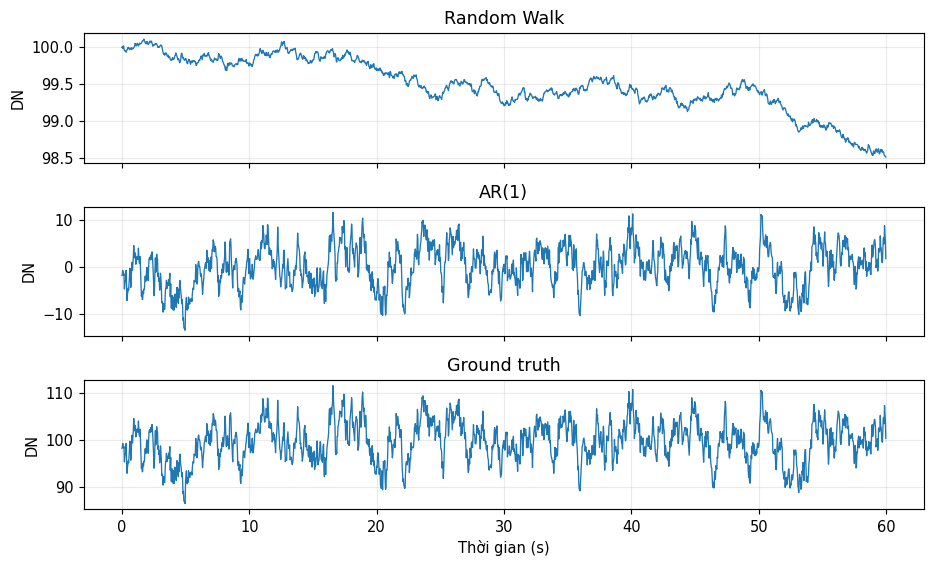

In [2]:
def random_walk(rng, n_samples, x0, sigma):
    """Random Walk có giá trị ban đầu xác định, sigma là std mỗi bước."""
    increments = rng.normal(0.0, sigma, n_samples - 1)
    return np.r_[x0, x0 + np.cumsum(increments)]


def generate_ar1(rng, n_samples, rho, sigma_f):
    """AR(1) khởi tạo dừng; sigma_f là std của quá trình, không phải w_f."""
    x_f = np.empty(n_samples)
    x_f[0] = rng.normal(0.0, sigma_f)
    sigma_wf = sigma_f * np.sqrt(1.0 - rho**2)
    w_f = rng.normal(0.0, sigma_wf, n_samples - 1)
    for n in range(1, n_samples):
        x_f[n] = rho * x_f[n - 1] + w_f[n - 1]
    return x_f


def generate_ground_truth(rng, cfg, n_samples, static=False, step=0.0):
    """Trả về các thành phần riêng biệt và tổng độ sáng x[n] (DN)."""
    x_s = random_walk(rng, n_samples, cfg.x0, cfg.sigma_s)
    x_f = generate_ar1(rng, n_samples, cfg.rho, cfg.sigma_f)
    if static:
        x_s[:] = cfg.x0
        x_f[:] = 0.0
    x_step = np.where(np.arange(n_samples) >= n_samples // 2, step, 0.0)
    return x_s, x_f, x_step, x_s + x_f + x_step


rng = np.random.default_rng(42)
t = np.arange(config.n_samples) / config.fs
x_s, x_f, x_step, x = generate_ground_truth(rng, config, len(t))
fig, ax = plt.subplots(3, 1, figsize=(9, 5.5), sharex=True)
for axis, values, label in zip(ax, (x_s, x_f, x),
                               ("Random Walk", "AR(1)", "Ground truth")):
    axis.plot(t, values, lw=0.9)
    axis.set(ylabel="DN", title=label)
ax[-1].set_xlabel("Thời gian (s)")
show_figure(fig, "02_ground_truth.png")

## 2.2–2.3. Mô hình cảm biến CMOS, Shot Noise, Read Noise, lượng tử và mức đen

Giả thiết RAW tuyến tính, không ISP, không thay đổi gain/exposure. Camera tham chiếu Basler a2A3536-31um: Mono12, system gain $K=0.353$ DN/e⁻, temporal dark noise quy về electron 3.664 e⁻ RMS (đã loại lượng tử). Mức nhiễu tối tương đương trước lượng tử $\sigma_r=K\times3.664\approx1.293$ DN. Datasheet đo ở cấu hình riêng, không phải phép đo của nhóm tại 30 FPS. Offset 16 DN và drift 0.05 DN/bước là giả thiết mô phỏng, không lấy từ datasheet.

$u[n]$ là kỳ vọng có điều kiện của tín hiệu quang đã chịu Flicker, chưa cộng mức đen hay nhiễu. Số quang điện tử kỳ vọng $\lambda_e[n]=u[n]/K$. Số thực tế $N_e[n]\mid u[n]\sim\mathrm{Poisson}(\lambda_e[n])$. Shot noise $v_{\rm shot}[n]=KN_e[n]-u[n]$ có kỳ vọng có điều kiện 0 và phương sai $Ku[n]$. Sinh Poisson trực tiếp, không dùng Gaussian để sinh dữ liệu.

Read noise $v_r[n]\sim\mathcal N(0,\sigma_r^2)$, kênh OB $v_{\rm ob}[n]\sim\mathcal N(0,\sigma_{\rm ob}^2)$; giả thiết độc lập giữa các mẫu/kênh và với các nguồn kích thích. $b[n]=b_0+d[n]$, $d[0]=0$, $d[n]=d[n-1]+w_d[n]$, $w_d[n]\sim\mathcal N(0,\sigma_d^2)$ độc lập. Drift không WSS.

Lượng tử hóa $Q_\Delta(a)=\Delta\,\mathrm{round}(a/\Delta)$ với $\Delta=1$ DN, giới hạn 0–4095. Khi không clipping và tín hiệu đủ biến động, sai số lượng tử xấp xỉ đều trên $[-\Delta/2,\Delta/2]$, phương sai $\Delta^2/12$. Không cộng thêm nhiễu Uniform trước phép làm tròn. Đếm clipping riêng (khác với sai số lượng tử).

In [3]:
def photon_noise(rng, u, system_gain):
    """Đếm quang điện tử Poisson và trả về nhiễu quy đổi sang DN."""
    u = np.asarray(u, dtype=float)
    if np.any(u < 0):
        raise ValueError("Tín hiệu quang âm; cần xem lại cấu hình mô phỏng.")
    lambda_e = u / system_gain
    n_e = rng.poisson(lambda_e)
    return n_e, system_gain * n_e - u


def quantize(signal_dn, cfg):
    """Lượng tử một lần, trả số đo float và số mẫu bị clipping."""
    rounded = np.rint(signal_dn)
    z = np.clip(rounded, 0, cfg.dn_max)
    return z, int(np.count_nonzero(z != rounded))


# Kiểm chứng quan hệ phương sai Shot Noise theo mức sáng.
rng = np.random.default_rng(123)
rows = []
for level in (20, 100, 200):
    _, v_shot = photon_noise(rng, np.full(100_000, level), config.system_gain)
    rows.append({"u (DN)": level, "Mean (DN)": v_shot.mean(),
                 "Var (DN²)": v_shot.var(ddof=1),
                 "Lý thuyết (DN²)": config.system_gain * level})
show_table(pd.DataFrame(rows), "shot_check.csv")

,u (DN),Mean (DN),Var (DN²),Lý thuyết (DN²)
0,20,-0.00602,7.03135,7.06
1,100,-0.00361,35.04967,35.30
2,200,0.00349,70.26282,70.60


## 2.4. Nhấp nháy, phơi sáng và chồng phổ

Một số driver đèn nối điện lưới 50 Hz có thành phần Flicker tại $f_F=2f_m=100$ Hz. Không phải mọi đèn đều như vậy. Mô hình chiếu sáng $L(t)=L_0(t)[1+m\cos(2\pi f_Ft+\Phi)]$, với $m=0.25$ là giả thiết. Phơi sáng là trung bình chuẩn hóa trên cửa sổ chữ nhật tâm $t_n=n/f_s$ (giả thiết mức sáng gần như không đổi trong $T_e$):

$$H_e(f)=\frac{\sin(\pi fT_e)}{\pi fT_e},\qquad f_a=\min_{k\in\mathbb Z}|f_F-kf_s|.$$

Ở 30 FPS, Nyquist 15 Hz, $f_a=10$ Hz; $H_e(100)\approx0.7568$ với $T_e=4$ ms. Không thể xác định duy nhất 100 Hz chỉ từ vạch 10 Hz. Phơi sáng làm suy giảm nhưng không loại hết Flicker. Mô hình thực hiện pha vật lý $\phi[n]$ bằng tích phân tần số, không tích lũy trị tuyệt đối tần số alias. Với tần số đổi chậm, dùng Sinc tại tần số tức thời là xấp xỉ cục bộ:

$$s[n]=mH_e(f_F[n])x[n]\cos\phi[n],\qquad u[n]=x[n]+s[n].$$

Pha ban đầu $\Phi\sim\mathcal U(0,2\pi)$ lấy một lần mỗi bản ghi. Khi biên độ $A$ và tần số không đổi, $s[n]=A\cos(\omega_a n+\Phi)$ là WSS với $E[s]=0$, $C_s[k]=A^2\cos(\omega_a k)/2$. Mô hình nhân với $x[n]$ biến thiên không nhất thiết WSS.

Flicker 100 Hz → 10 Hz; H_e=0.756827; A=18.921 DN


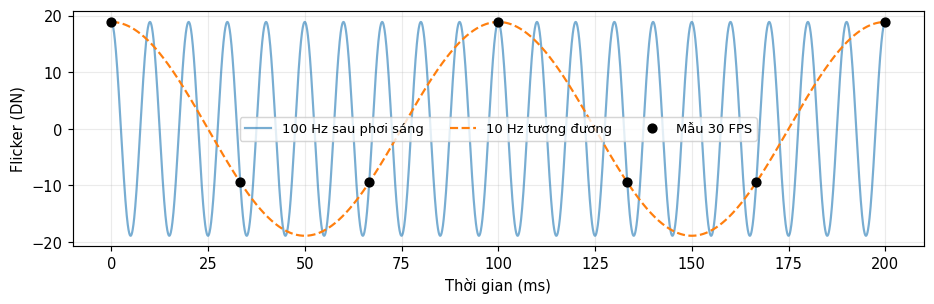

In [4]:
def alias_frequency(f, fs):
    """Tần số quan sát không âm trong dải [0, fs/2]."""
    return np.abs((np.asarray(f) + fs / 2) % fs - fs / 2)


def generate_flicker(rng, x, cfg, modulation, grid_drift):
    """Điều chế nhân; hỗ trợ lưới đổi tần số tuyến tính."""
    f_F = 2.0 * np.linspace(cfg.fm, cfg.fm + grid_drift, len(x))
    phi0 = rng.uniform(0.0, 2 * np.pi)
    # Tích phân hình thang của tần số vật lý giữa hai khung hình.
    dphi = np.pi * (f_F[1:] + f_F[:-1]) / cfg.fs
    phi = phi0 + np.r_[0.0, np.cumsum(dphi)]
    s = modulation * np.sinc(f_F * cfg.te) * x * np.cos(phi)
    return s, f_F


f_F = 2 * config.fm
f_a = float(alias_frequency(f_F, config.fs))
he = np.sinc(f_F * config.te)
A = config.m * he * config.x0
print(f"Flicker {f_F:g} Hz → {f_a:g} Hz; H_e={he:.6f}; A={A:.3f} DN")
t_cont = np.linspace(0, 0.2, 3000)
t_sample = np.arange(7) / config.fs
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(t_cont * 1000, A * np.cos(2 * np.pi * f_F * t_cont),
        alpha=0.6, label="100 Hz sau phơi sáng")
ax.plot(t_cont * 1000, A * np.cos(2 * np.pi * f_a * t_cont),
        "--", label="10 Hz tương đương")
ax.plot(t_sample * 1000, A * np.cos(2 * np.pi * f_F * t_sample),
        "ko", label="Mẫu 30 FPS")
ax.set(xlabel="Thời gian (ms)", ylabel="Flicker (DN)")
ax.legend(ncol=3, fontsize=9)
show_figure(fig, "02_aliasing.png")

## 2.5–2.8. Mô hình số đo hai kênh và kịch bản

$$a_1[n]=KN_e[n]+b[n]+v_r[n],\qquad a_2[n]=b[n]+v_{\rm ob}[n].$$
$$z_i[n]=\mathrm{clip}(Q_\Delta(a_i[n]),0,4095),\quad i=1,2.$$

Khi không clipping, dạng cộng tương đương là

$$z_1[n]=x[n]+s[n]+b[n]+v_1[n],\qquad z_2[n]=b[n]+v_2[n].$$

$R_1[n]\approx Ku[n]+\sigma_r^2+\Delta^2/12$, $R_2\approx\sigma_{\rm ob}^2+\Delta^2/12$. Baseline Raw $y[n]=z_1[n]-z_2[n]$ loại mức đen chung, nhưng cộng nhiễu riêng hai kênh. OB giúp tách nền và mức đen, vốn cùng động học Random Walk; đây là giả thiết thiết kế kênh đo.

| Kịch bản | Điều kiện |
|---|---|
| C0 | Độ sáng cố định, không Flicker (kiểm tra giới hạn đơn giản) |
| S0 | Random Walk + AR(1), Flicker danh nghĩa |
| S1 | S0 và bước sáng +20 DN tại n=900 (30 s) |
| S2 | S0 và tần số lưới tăng tuyến tính 50 → 50.3 Hz |

Tất cả dùng 1.800 mẫu; tách các thay đổi để đánh giá từng nguyên nhân. Offset, read, shot, drift và lượng tử vẫn có ở C0. Tham số ngoài camera tham chiếu là giả thiết khảo sát. Không đưa ground truth cho bộ lọc ở Chương 5–6.

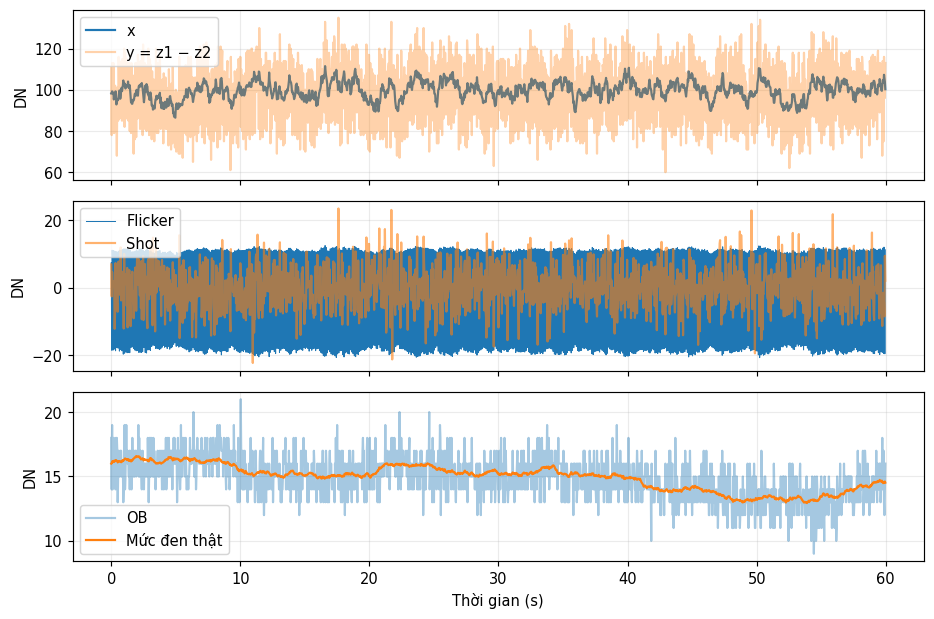

,Scenario,Std flicker,Std shot,Raw RMSE,Clip z1,Clip z2
0,C0,0.00000,6.11192,6.37473,0,0
1,S0,13.34370,6.10222,14.53059,0,0
2,S1,14.74392,6.38934,16.00376,0,0
3,S2,13.32148,6.07414,14.61947,0,0


In [5]:
def sensor_measurements(rng, u, b, cfg):
    """Tạo hai số đo từ kỳ vọng quang và mức đen chung."""
    n_e, v_shot = photon_noise(rng, u, cfg.system_gain)
    v_r = rng.normal(0.0, cfg.sigma_r, len(u))
    v_ob = rng.normal(0.0, cfg.sigma_ob, len(u))
    a1 = cfg.system_gain * n_e + b + v_r
    a2 = b + v_ob
    z1, clip1 = quantize(a1, cfg)
    z2, clip2 = quantize(a2, cfg)
    return {"z1": z1, "z2": z2, "v_shot": v_shot, "v_r": v_r,
            "v_ob": v_ob, "v_q1": np.rint(a1) - a1,
            "v_q2": np.rint(a2) - a2, "clip1": clip1, "clip2": clip2}


def simulate(seed, scenario="S0", cfg=config, modulation=None,
             grid_drift=None, static=None):
    """Sinh bản ghi độc lập; các override chỉ dùng cho thí nghiệm độ nhạy."""
    if scenario not in ("C0", "S0", "S1", "S2"):
        raise ValueError(f"Kịch bản không hợp lệ: {scenario}")
    rng = np.random.default_rng(seed)
    n = cfg.n_samples
    if static is None:
        static = scenario == "C0"
    if modulation is None:
        modulation = 0.0 if scenario == "C0" else cfg.m
    if grid_drift is None:
        grid_drift = cfg.grid_drift if scenario == "S2" else 0.0
    step = cfg.step_dn if scenario == "S1" else 0.0
    x_s, x_f, x_step, x = generate_ground_truth(rng, cfg, n, static, step)
    s, f_F = generate_flicker(rng, x, cfg, modulation, grid_drift)
    u = x + s
    b = random_walk(rng, n, cfg.b0, cfg.sigma_d)
    out = sensor_measurements(rng, u, b, cfg)
    out.update(t=np.arange(n) / cfg.fs, x_s=x_s, x_f=x_f, x_step=x_step,
               x=x, s=s, u=u, b=b, f_F=f_F, seed=seed, scenario=scenario)
    out["y"] = out["z1"] - out["z2"]
    return out


def rmse(error, axis=-1):
    """RMSE từ sai số; axis cuối là thời gian mặc định."""
    return np.sqrt(np.mean(np.square(error), axis=axis))


example = simulate(42)
fig, ax = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
ax[0].plot(example["t"], example["x"], label="x")
ax[0].plot(example["t"], example["y"], alpha=0.35, label="y = z1 − z2")
ax[0].legend()
ax[0].set_ylabel("DN")
ax[1].plot(example["t"], example["s"], lw=0.7, label="Flicker")
ax[1].plot(example["t"], example["v_shot"], alpha=0.6, label="Shot")
ax[1].legend()
ax[1].set_ylabel("DN")
ax[2].plot(example["t"], example["z2"], alpha=0.4, label="OB")
ax[2].plot(example["t"], example["b"], label="Mức đen thật")
ax[2].legend()
ax[2].set(xlabel="Thời gian (s)", ylabel="DN")
show_figure(fig, "02_measurements.png")

rows = []
for scenario in ("C0", "S0", "S1", "S2"):
    d = simulate(42, scenario)
    assert np.allclose(d["x"], d["x_s"] + d["x_f"] + d["x_step"])
    assert np.all(d["u"] >= 0) and np.all(np.isfinite(d["z1"]))
    rows.append({"Scenario": scenario, "Std flicker": d["s"].std(),
                 "Std shot": d["v_shot"].std(), "Raw RMSE": rmse(d["y"]-d["x"]),
                 "Clip z1": d["clip1"], "Clip z2": d["clip2"]})
show_table(pd.DataFrame(rows), "simulation_check.csv")
# Seed và dữ liệu xác định được; không cần nộp tệp NPZ riêng.

# Chương 3. Đặc trưng thống kê của tín hiệu

## 3.1. Mean, Variance và tính dừng WSS

Trung bình mẫu $\bar y=N^{-1}\sum_n y[n]$, phương sai mẫu $s_y^2=(N-1)^{-1}\sum_n(y[n]-\bar y)^2$. Mẫu số N−1 không bảo đảm không chệch khi các mẫu tương quan. Với dữ liệu tương quan, không dùng công thức sai số trung bình IID một cách máy móc. Với WSS, $\mathrm{Var}(\bar y)=N^{-1}[C_y[0]+2\sum_{k=1}^{N-1}(1-k/N)C_y[k]]$. Ở đây dùng 30 bản ghi **hiệu chuẩn thống kê riêng** (seed 50–79), điều kiện nền cố định, Flicker cố định pha ngẫu nhiên và AR(1) dừng, mức đen cố định, để kiểm tra độ bất định của thống kê hữu hạn. Std giữa các bản ghi là độ phân tán của ước lượng; CI 95% cho trung bình của 30 ước lượng dùng phân bố t, không phải CI của một bản ghi.

| Thành phần | WSS? |
|---|---|
| AR(1) khởi tạo dừng, read noise | Có theo giả thiết |
| Flicker pha ngẫu nhiên, A và f cố định | Có |
| Shot noise | Phụ thuộc mức sáng có điều kiện; không mặc định WSS |
| Random Walk, drift, bước sáng | Không |
| S0/S1/S2 | Không WSS toàn bản ghi; Welch/ACF là mô tả hữu hạn, không phải PSD WSS chính xác |

## 3.2. Tự tương quan (ACF) và mật độ phổ công suất (PSD)

Dùng tự hiệp phương sai mẫu dạng biased (chia N) và ACF chuẩn hóa:

$$\hat C_y[k]=\frac1N\sum_{n=0}^{N-k-1}(y[n]-\bar y)(y[n+k]-\bar y),\quad \hat\rho_y[k]=\hat C_y[k]/\hat C_y[0].$$

Chỉ xem ACF khi phương sai dương; $\hat C_y[0]$ dùng mẫu số N, không nhầm với phương sai mẫu chia N−1. Kỳ vọng: AR(1) giảm theo hàm mũ, Flicker có chu kỳ 3 mẫu, read noise gần trắng. Phổ Welch một phía (DN²/Hz): cửa sổ Hann, chồng 50%, detrend hằng mỗi đoạn. Khoảng cách bin $\Delta f=f_s/L$; L dài phân giải cao hơn nhưng số đoạn ít hơn, phương sai phổ lớn hơn. So sánh L = 64, 256, 1024 trên bản ghi S0; chọn 256 cho mô tả phổ tổng thể, dùng FFT zero-padding + LS ở Chương 4 để ước lượng tần số chính xác hơn. Không coi zero-padding là tăng độ phân giải vật lý.

,Thống kê,Mean MC,Std MC,CI95 half-width
0,Mean (DN),99.92307,0.38488,0.14372
1,Variance (DN²),234.10984,5.63182,2.10296


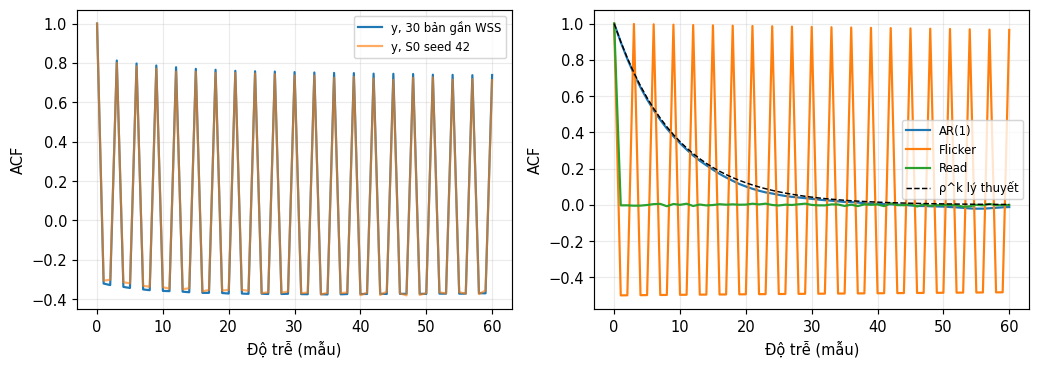

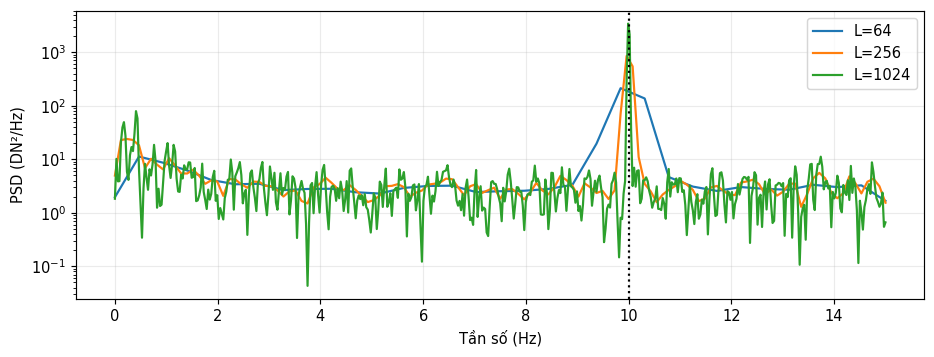

,L,Bin (Hz),Số đoạn,Peak (Hz)
0,64,0.46875,55,9.84375
1,256,0.11719,13,9.96094
2,1024,0.02930,2,9.99023


In [6]:
def autocov(x, max_lag):
    """Tự hiệp phương sai mẫu biased, hỗ trợ batch theo trục cuối."""
    x = np.asarray(x, dtype=float)
    n = x.shape[-1]
    if not 0 <= max_lag < n:
        raise ValueError("max_lag phải nhỏ hơn số mẫu")
    centered = x - x.mean(axis=-1, keepdims=True)
    values = [np.sum(centered[..., :n-k] * centered[..., k:], axis=-1) / n
              for k in range(max_lag + 1)]
    return np.stack(values, axis=-1)


def acf(x, max_lag):
    """ACF chuẩn hóa; chuỗi hằng có ACF không xác định (NaN)."""
    cov = autocov(x, max_lag)
    return np.divide(cov, cov[..., :1], out=np.full_like(cov, np.nan),
                     where=cov[..., :1] > 0)


def mean_ci(values):
    """Trung bình, std giữa realization và nửa độ rộng CI t 95%."""
    a = np.asarray(values, dtype=float)
    sd = a.std(ddof=1)
    half = stats.t.ppf(0.975, len(a) - 1) * sd / np.sqrt(len(a))
    return a.mean(), sd, half


# Thí nghiệm gần WSS: khóa nền và drift, giữ AR(1) và Flicker danh nghĩa.
stationary_cfg = replace(config, sigma_s=0.0, sigma_d=0.0)
records = [simulate(seed, cfg=stationary_cfg) for seed in range(50, 80)]
ys = np.stack([d["y"] for d in records])
rows = []
for name, values in (("Mean (DN)", ys.mean(axis=1)),
                     ("Variance (DN²)", ys.var(axis=1, ddof=1))):
    avg, sd, half = mean_ci(values)
    rows.append({"Thống kê": name, "Mean MC": avg, "Std MC": sd,
                 "CI95 half-width": half})
show_table(pd.DataFrame(rows), "statistics.csv")
# So sánh ACF ensemble của các thành phần với số đo S0 một bản ghi.
lag = np.arange(61)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(lag, acf(ys, 60).mean(axis=0), label="y, 30 bản gần WSS")
ax[0].plot(lag, acf(example["y"], 60), alpha=0.65, label="y, S0 seed 42")
ax[0].set(xlabel="Độ trễ (mẫu)", ylabel="ACF")
ax[0].legend(fontsize=8)
for key, name in (("x_f", "AR(1)"), ("s", "Flicker"), ("v_r", "Read")):
    a = np.stack([d[key] for d in records])
    ax[1].plot(lag, acf(a, 60).mean(axis=0), label=name)
ax[1].plot(lag, config.rho**lag, "k--", lw=1, label="ρ^k lý thuyết")
ax[1].set(xlabel="Độ trễ (mẫu)", ylabel="ACF")
ax[1].legend(fontsize=8)
show_figure(fig, "03_acf.png")

fig, ax = plt.subplots(figsize=(9, 3.5))
rows = []
for L in (64, 256, 1024):
    f, psd = signal.welch(example["y"], fs=config.fs, window="hann",
                          nperseg=L, noverlap=L//2, scaling="density")
    ax.semilogy(f, psd, label=f"L={L}")
    peak = np.argmax(np.where(f >= 2, psd, -np.inf))
    rows.append({"L": L, "Bin (Hz)": config.fs / L,
                 "Số đoạn": 1 + (len(example["y"]) - L)//(L-L//2),
                 "Peak (Hz)": f[peak]})
ax.axvline(10, ls=":", color="black")
ax.set(xlabel="Tần số (Hz)", ylabel="PSD (DN²/Hz)")
ax.legend()
show_figure(fig, "03_welch.png")
show_table(pd.DataFrame(rows), "welch.csv")

**Nhận xét:** ACF của Flicker có dạng tuần hoàn, còn AR(1) suy giảm. Vạch phổ tại vùng 10 Hz phù hợp aliasing dự kiến. Thành phần phổ thấp tần chứa biến động thật và có thể chứa drift dư; không thể gán toàn bộ cho nhiễu. Bảng độ bất định trên chỉ áp dụng cho điều kiện gần WSS đã kiểm soát.

# Chương 4. Ước lượng và hiệu chuẩn tham số

Hiệu chuẩn dùng các bản ghi riêng, với điều kiện chiếu sáng và động học được kiểm soát trong mô phỏng. Các giá trị thật chỉ dùng để sinh dữ liệu và đối chiếu; hàm ước lượng nhận số đo và các điều kiện thí nghiệm, không nhận ground truth. Đây là hiệu chuẩn **mô phỏng** chứ không phải hiệu chuẩn camera thực. Nền Random Walk chậm $\sigma_s$ được xem là giả thiết thiết kế; phương sai trạng thái nền trong bộ lọc được chọn bằng validation, không tuyên bố đo được từ số đo.

## 4.1. Dark calibration và Photon Transfer Curve (PTC)

Trong chế độ che sáng và ổn định nhiệt (drift tắt), $\hat b_0=\bar z_2$, $\hat R_2=s_{z_2}^2$, $\hat R_{\rm dark,1}=s_{z_1}^2$ (gồm lượng tử). $\hat\sigma_r=\sqrt{\hat R_{\rm dark,1}-1/12}$ nếu hiệu dương. Với các mức sáng không Flicker, không RW/AR(1), offset cố định:

$$\mu_i\approx\overline z_{1,i}-\hat b_0,\qquad V_i\approx K\mu_i+R_{\rm dark,1}.$$

Dùng LS với intercept độc lập từ phép đo tối, $\hat K=\arg\min_{K\ge0}\sum_i(V_i-\hat R_{\rm dark,1}-K\mu_i)^2$. Đây là hồi quy trên phương sai ước lượng, không gọi là ML chính xác. Không trừ OB variance lần nữa vì PTC dùng trực tiếp $z_1$, không dùng $z_1-z_2$. Mức chiếu sáng trải rộng để nhận dạng hệ số góc nhưng tránh bão hòa. Mỗi mức 6.000 khung.

In [7]:
def dark_calibration(rng, cfg, n=6000):
    """Đo hai kênh che sáng, mức đen giữ cố định."""
    d = sensor_measurements(rng, np.zeros(n), np.full(n, cfg.b0), cfg)
    if d["clip1"] + d["clip2"]:
        raise RuntimeError("Dark calibration bị clipping.")
    return d["z2"].mean(), d["z1"].var(ddof=1), d["z2"].var(ddof=1)


def ptc_calibration(rng, cfg, b_hat, R_dark, n=6000):
    """PTC: chỉ sử dụng mean/variance của số đo tại các mức sáng."""
    levels = np.array([20, 50, 100, 200, 400, 800])
    means, variances = [], []
    for level in levels:
        d = sensor_measurements(rng, np.full(n, level), np.full(n, cfg.b0), cfg)
        if d["clip1"]:
            raise RuntimeError("PTC bị clipping.")
        means.append(d["z1"].mean() - b_hat)
        variances.append(d["z1"].var(ddof=1))
    means, variances = np.array(means), np.array(variances)
    gain = np.dot(means, variances-R_dark) / np.dot(means, means)
    if gain <= 0:
        raise RuntimeError("PTC không nhận dạng được gain dương.")
    return gain, means, variances

## 4.2. Tần số, biên độ và pha Flicker bằng Least Squares

Thu một bản ghi 6.000 khung ở mức sáng ổn định có Flicker danh nghĩa, offset cố định. Với $y=z_1-z_2$, khớp

$$y[n]\approx c+a_c\cos(2\pi fn/f_s)+a_s\sin(2\pi fn/f_s).$$

FFT zero-padding xác định vùng tìm kiếm; mỗi f thử giải LS tuyến tính theo $c,a_c,a_s$, sau đó tối thiểu hóa tổng bình phương phần dư theo f. $\hat A=\sqrt{\hat a_c^2+\hat a_s^2}$, $\hat\Phi=\mathrm{atan2}(-\hat a_s,\hat a_c)$, $\hat x_0=\hat c$. Tần số alias được nhận dạng trực tiếp, không suy ra duy nhất tần số vật lý. OLS dùng như xấp xỉ vì shot noise phụ thuộc tín hiệu. Pha từ bản ghi hiệu chuẩn không dùng để khởi tạo pha bản ghi test.

In [8]:
def fit_sine(y, fs):
    """Variable projection: tìm tần số, LS hệ số DC/cos/sin."""
    n = np.arange(len(y))
    nfft = 8 * 2**int(np.ceil(np.log2(len(y))))
    freqs = np.fft.rfftfreq(nfft, 1/fs)
    spectrum = np.abs(np.fft.rfft(y-y.mean(), nfft))
    # Tìm trong dải có thể quan sát; loại DC và sát Nyquist.
    valid = (freqs >= 1.0) & (freqs <= fs/2-0.1)
    f0 = freqs[np.argmax(np.where(valid, spectrum, -np.inf))]

    def solve(f):
        phase = 2 * np.pi * f * n / fs
        D = np.column_stack((np.ones(len(y)), np.cos(phase), np.sin(phase)))
        theta = np.linalg.lstsq(D, y, rcond=None)[0]
        residual = y - D @ theta
        return theta, residual

    def objective(f):
        residual = solve(f)[1]
        return np.dot(residual, residual)

    width = fs / len(y)
    fit = optimize.minimize_scalar(objective, method="bounded",
                                   bounds=(f0-width, f0+width),
                                   options={"xatol": 1e-10})
    c, a_c, a_s = solve(fit.x)[0]
    A_hat = float(np.hypot(a_c, a_s))
    phi_hat = float(np.arctan2(-a_s, a_c))
    return float(fit.x), A_hat, float(c), phi_hat


def flicker_calibration(rng, cfg, n=6000):
    """Cảnh ổn định có Flicker, độc lập với tập validation/test."""
    x = np.full(n, cfg.x0)
    s, _ = generate_flicker(rng, x, cfg, cfg.m, 0.0)
    d = sensor_measurements(rng, x+s, np.full(n, cfg.b0), cfg)
    if d["clip1"] + d["clip2"]:
        raise RuntimeError("Bản ghi hiệu chuẩn Flicker bị clipping.")
    y = d["z1"] - d["z2"]
    f_hat, A_hat, x0_hat, phi_hat = fit_sine(y, cfg.fs)
    return f_hat, A_hat, x0_hat, phi_hat, y

## 4.3. Drift mức đen bằng Allan variance

Với kênh OB $z_2=b+v_2$, $b$ là Random Walk với phương sai bước $q_d=\sigma_d^2$, $v_2$ trắng có phương sai $R_2$. Lấy trung bình của hai khối M mẫu liên tiếp, gọi $\bar z_{i,M}$ là trung bình khối bắt đầu ở i. Allan variance chồng lấp:

$$\hat\sigma_A^2(M)=\frac{1}{2(N-2M+1)}\sum_{i=0}^{N-2M}(\bar z_{i+M,M}-\bar z_{i,M})^2.$$

Với Random Walk rời rạc + nhiễu trắng độc lập, kỳ vọng là $R_2/M+q_d(2M^2+1)/(6M)$. Lấy $\hat R_2$ từ phép đo tối độc lập, khớp $q_d\ge0$ bằng LS có trọng số tương đối. Dùng tám bản ghi 60 s độc lập để tăng ổn định và tránh tích lũy drift quá dài. Nếu ước lượng chạm biên 0, ghi nhận; không coi đó là bằng chứng drift bằng 0. Độ bất định thực nghiệm đánh giá bằng lặp lại toàn bộ hiệu chuẩn.

## 4.4. AR(1) của độ sáng thực

Trong phép hiệu chuẩn có điều kiện chiếu sáng không Flicker và nền giữ cố định, vẫn có biến động ngắn hạn AR(1). Giả thiết nhiễu đo trắng có điều kiện, mức đen được loại qua $y=z_1-z_2$. Tự hiệp phương sai tại lag dương $C_y[k]\approx \sigma_f^2\rho^k$ với $k\ge1$ (lag 0 chứa thêm phương sai nhiễu đo). Dùng LS phi tuyến trực tiếp trên covariance, không lấy log các giá trị âm hoặc ép chúng thành số dương. Tám bản ghi 60 s độc lập; ước lượng từ số đo, không từ chuỗi $x_f$ thật. Đây là điều kiện hiệu chuẩn lý tưởng hóa khó bố trí trên camera thực.

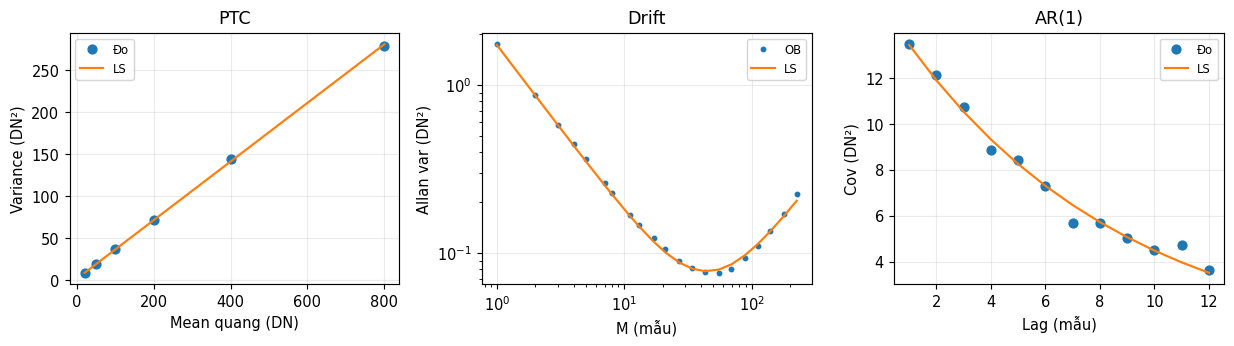

In [9]:
def allan_variance(z, block_sizes):
    """Allan variance chồng lấp; z có shape (records, samples)."""
    z = np.atleast_2d(z)
    cumulative = np.c_[np.zeros(len(z)), np.cumsum(z, axis=1)]
    values = []
    for M in block_sizes:
        averages = (cumulative[:, M:] - cumulative[:, :-M]) / M
        difference = averages[:, M:] - averages[:, :-M]
        values.append(0.5 * np.mean(difference**2))
    return np.array(values)


def drift_calibration(rng, cfg, R2, repeats=8):
    """Ước lượng q_d từ các bản ghi OB, R2 từ dark calibration."""
    n = cfg.n_samples
    traces = []
    for _ in range(repeats):
        b = random_walk(rng, n, cfg.b0, cfg.sigma_d)
        z2, clipped = quantize(b+rng.normal(0, cfg.sigma_ob, n), cfg)
        if clipped:
            raise RuntimeError("Bản ghi hiệu chuẩn drift bị clipping.")
        traces.append(z2)
    M = np.unique(np.rint(np.geomspace(1, n//8, 24)).astype(int))
    av = allan_variance(np.stack(traces), M)
    basis = (2.0 * M**2 + 1) / (6*M)
    # LS tương đối: phương sai Allan trải qua nhiều bậc độ lớn.
    weight = 1.0 / av
    design = (basis * weight)[:, None]
    target = (av - R2/M) * weight
    q_d = float(optimize.lsq_linear(design, target, bounds=(0, np.inf)).x[0])
    return q_d, M, av


def ar1_calibration(rng, cfg, repeats=8):
    """Fit covariance lag dương của số đo có AR(1), không dùng x_f thật."""
    traces = []
    n = cfg.n_samples
    for _ in range(repeats):
        x = cfg.x0 + generate_ar1(rng, n, cfg.rho, cfg.sigma_f)
        d = sensor_measurements(rng, x, np.full(n, cfg.b0), cfg)
        traces.append(d["z1"] - d["z2"])
    lag = np.arange(1, 13)
    cov = autocov(np.stack(traces), lag[-1]).mean(axis=0)[1:]

    def residual(theta):
        variance, rho = theta
        return variance * rho**lag - cov

    fit = optimize.least_squares(residual, [max(cov[0], 1), 0.8],
                                 bounds=([1e-6, 0.01], [1e4, 0.999]))
    variance, rho = fit.x
    return float(rho), float(np.sqrt(variance)), lag, cov


def calibrate(seed, cfg=config, details=False):
    """Tạo dữ liệu hiệu chuẩn riêng và trả các tham số đã nhận dạng."""
    rng = np.random.default_rng(seed)
    b_hat, R_dark, R2 = dark_calibration(rng, cfg)
    K_hat, means, variances = ptc_calibration(rng, cfg, b_hat, R_dark)
    f_hat, A_hat, x0_hat, phi_hat, y = flicker_calibration(rng, cfg)
    q_d, M, av = drift_calibration(rng, cfg, R2)
    rho, sigma_f, lag, cov = ar1_calibration(rng, cfg)
    result = {"b0": b_hat, "R_dark": R_dark, "R2": R2, "K": K_hat,
              "f_alias": f_hat, "A": A_hat, "x0": x0_hat, "rho": rho,
              "sigma_f": sigma_f, "sigma_d": np.sqrt(q_d), "q_d": q_d,
              "sigma_r": np.sqrt(max(R_dark-1/12, 0))}
    if details:
        return result, (means, variances, M, av, lag, cov, phi_hat, y)
    return result


cal, details = calibrate(11, details=True)
means, variances, M, av, lag, cov, phi_hat, y_cal = details
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].plot(means, variances, "o", label="Đo")
ax[0].plot(means, cal["K"]*means+cal["R_dark"], label="LS")
ax[0].set(xlabel="Mean quang (DN)", ylabel="Variance (DN²)", title="PTC")
ax[1].loglog(M, av, "o", ms=3, label="OB")
ax[1].loglog(M, cal["R2"]/M+cal["q_d"]*(2*M**2+1)/(6*M), label="LS")
ax[1].set(xlabel="M (mẫu)", ylabel="Allan var (DN²)", title="Drift")
ax[2].plot(lag, cov, "o", label="Đo")
ax[2].plot(lag, cal["sigma_f"]**2*cal["rho"]**lag, label="LS")
ax[2].set(xlabel="Lag (mẫu)", ylabel="Cov (DN²)", title="AR(1)")
for axis in ax:
    axis.legend(fontsize=8)
show_figure(fig, "04_calibration.png")

## 4.5. Độ bất định của tham số hiệu chuẩn

Lặp lại thí nghiệm hiệu chuẩn trên 30 bộ dữ liệu độc lập (seed 500–529). So sánh tham số từ seed 11 với giá trị dùng để sinh dữ liệu. Bias MC = trung bình 30 ước lượng trừ tham số thật; std MC = độ phân tán giữa 30 ước lượng; CI95 half-width là nửa khoảng tin cậy t cho trung bình MC. Độ phân tán không phải khoảng tin cậy của từng ước lượng. Bộ lọc dùng riêng `cal` seed 11; các lần lặp không được dùng để chọn kết quả đẹp hơn.

In [10]:
cal_mc = pd.DataFrame([calibrate(seed) for seed in range(500, 530)])
R_dark_true = config.sigma_r**2 + 1/12
truth = {"b0": config.b0, "R_dark": R_dark_true,
         "R2": config.sigma_ob**2+1/12, "K": config.system_gain,
         "f_alias": float(alias_frequency(2*config.fm, config.fs)),
         "A": config.m*abs(np.sinc(2*config.fm*config.te))*config.x0,
         "x0": config.x0, "rho": config.rho, "sigma_f": config.sigma_f,
         "sigma_d": config.sigma_d, "q_d": config.sigma_d**2,
         "sigma_r": config.sigma_r}
rows = []
for key, ref in truth.items():
    avg, sd, half = mean_ci(cal_mc[key])
    rows.append({"Parameter": key, "Reference": ref,
                 "Estimate seed 11": cal[key], "MC mean": avg,
                 "MC bias": avg-ref, "MC std": sd,
                 "CI95 half-width": half})
cal_table = pd.DataFrame(rows)
show_table(cal_table, "calibration.csv")
cal_mc.to_csv(RESULT_DIR / "calibration_trials.csv", index=False)

,Parameter,Reference,Estimate seed 11,MC mean,MC bias,MC std,CI95 half-width
0,b0,16.00000,15.99183,15.99161,-0.00839,0.01549,0.00578
1,R_dark,1.75620,1.76984,1.75913,0.00293,0.03201,0.01195
2,R2,1.75620,1.72972,1.76260,0.00640,0.04080,0.01523
3,K,0.35300,0.34919,0.35294,-0.00006,0.00473,0.00177
4,f_alias,10.00000,10.00002,10.00000,0.00000,0.00002,0.00001
5,A,18.92067,19.06437,18.92229,0.00162,0.12935,0.04830
6,x0,100.00000,100.00202,100.01478,0.01478,0.08582,0.03205
7,rho,0.90000,0.88514,0.89608,-0.00392,0.00705,0.00263
8,sigma_f,4.00000,3.89793,3.95578,-0.04422,0.09078,0.03390
9,sigma_d,0.05000,0.05120,0.04892,-0.00108,0.00299,0.00111


# Chương 5. Thiết kế các phương pháp ước lượng

## 5.1. Baseline và cơ sở lựa chọn Kalman

Raw: $\hat x[n]=y[n]=z_1[n]-z_2[n]$. Moving Average nhân quả, cửa sổ M mẫu, $\hat x[n]=\sum_{i=0}^{\min(n,M-1)}y[n-i]/\min(n+1,M)$. Không dùng mẫu tương lai. MA3 có thể triệt sinusoid 10 Hz lý tưởng vì chu kỳ 3 khung; MA dài có thể làm suy giảm biến động thật và gây trễ.

Chọn Kalman vì độ sáng/mức đen có động học và không dừng toàn bản ghi. Không cần RLS/RIV thích nghi trong phạm vi hai phương án chính; kiểm tra sai lệch tần số ở Chương 6. Kalman tuyến tính là xấp xỉ cho shot noise phụ thuộc tín hiệu và Flicker nhân, không khẳng định tối ưu tuyệt đối.

## 5.2. KF3 — Không có trạng thái Flicker

$$\mathbf X_3=[x_s^*,x_f,b]^T,\qquad x_s^*=x_s+x_{\rm step}.$$
$$F_3=\mathrm{diag}(1,\hat\rho,1),\quad H_3=\begin{bmatrix}1&1&1\\0&0&1\end{bmatrix},$$
$$Q_3=\mathrm{diag}(q_x,(1-\hat\rho^2)\hat\sigma_f^2,\hat q_d),\qquad R_3=\mathrm{diag}(\hat R_{1,0}+\hat A^2/2,\hat R_2).$$

$\hat R_{1,0}=\hat K\hat x_0+\hat R_{\rm dark,1}$: phương sai nhiễu cảm biến ở điểm làm việc hiệu chuẩn, đã gồm lượng tử. Flicker được coi là nhiễu đo trắng tương đương theo công suất; giả thiết cố ý đơn giản hóa và sai về tương quan. $q_x$ là tham số thiết kế nền, dùng chung KF3/KF5; không nhất thiết bằng phương sai bước nền thật. Step không được báo trước, bộ lọc phải bám bằng số đo.

## 5.3. KF5 — Có trạng thái Flicker AR(2)

$$\mathbf X_5=[x_s^*,x_f,b,s[n],s[n-1]]^T.$$
$$s[n]=a_1s[n-1]+a_2s[n-2]+w_F[n],\quad a_1=2r\cos\hat\omega_a,\quad a_2=-r^2,$$

với $\hat\omega_a=2\pi\hat f_a/f_s$, $0<r<1$. AR(2) cộng hưởng xấp xỉ Flicker có biên độ biến thiên; không coi đây là mô hình vật lý chính xác. Với phương sai dừng đích $\sigma_F^2=\hat A^2/2$, phương sai kích thích suy từ phương trình Yule–Walker:

$$q_F=\sigma_F^2\frac{(1+a_2)[(1-a_2)^2-a_1^2]}{1-a_2}.$$

$$F_5=\begin{bmatrix}1&0&0&0&0\\0&\hat\rho&0&0&0\\0&0&1&0&0\\0&0&0&a_1&a_2\\0&0&0&1&0\end{bmatrix},\quad H_5=\begin{bmatrix}1&1&1&1&0\\0&0&1&0&0\end{bmatrix},$$
$$Q_5=\mathrm{diag}(q_x,(1-\hat\rho^2)\hat\sigma_f^2,\hat q_d,q_F,0),\quad R_5=\mathrm{diag}(\hat R_{1,0},\hat R_2).$$

KF5 không cộng công suất Flicker vào R vì đã mô hình hóa trong trạng thái. Cả hai cho $\hat x=\hat x_s^*+\hat x_f$. Tất cả tham số nhận dạng dùng từ hiệu chuẩn seed 11. Tần số cố định, không thích nghi; cả C0 (không Flicker) vẫn dùng bộ lọc thiết kế danh nghĩa để kiểm tra mismatch.

## 5.4. Thuật toán Kalman rời rạc

Với prior $\hat X_{n|n-1}$, $P_n^-$, số đo $z_n=[z_1,z_2]^T$:

$$\begin{aligned}\hat X^-_n&=F\hat X_{n-1},&P^-_n&=FP_{n-1}F^T+Q,\\ e_n&=z_n-H\hat X^-_n,&S_n&=HP^-_nH^T+R,\\ K_n&=P^-_nH^TS_n^{-1},&\hat X_n&=\hat X^-_n+K_ne_n,\\ P_n&=(I-K_nH)P^-_n(I-K_nH)^T+K_nRK_n^T.\end{aligned}$$

Dùng `solve` thay nghịch đảo trực tiếp, cập nhật Joseph cho covariance. Khởi tạo prior tại n=0 từ hiệu chuẩn (không dùng số đo test hai lần); prior nền có std 20 DN, mức đen 5 DN, AR(1) dùng variance đã hiệu chuẩn, Flicker dùng covariance dừng AR(2). Vì F/H/Q/R cố định, covariance/gain không phụ thuộc giá trị số đo; tính trước gain cho từng n rồi lọc nhiều bản ghi song song để giảm thời gian, nhưng vẫn nhân quả theo n. Burn-in 150 mẫu (5 s) dùng chung cho mọi phương pháp.

In [11]:
def causal_ma(y, M):
    """Trung bình trượt nhân quả; batch trên các bản ghi nếu cần."""
    y = np.atleast_2d(y)
    cs = np.c_[np.zeros(len(y)), np.cumsum(y, axis=1)]
    hi = np.arange(1, y.shape[1]+1)
    lo = np.maximum(0, hi-M)
    return (cs[:, hi]-cs[:, lo])/(hi-lo)


def make_model(cal, fs, q_x, r=None, R_scale=1.0):
    """Dựng F, H, Q, R và prior từ hiệu chuẩn, không từ truth test."""
    rho, sigma_f = cal["rho"], cal["sigma_f"]
    q_f = (1-rho**2)*sigma_f**2
    R1 = cal["K"]*cal["x0"] + cal["R_dark"]
    var_s = cal["A"]**2/2
    if r is None:
        F = np.diag([1.0, rho, 1.0])
        H = np.array([[1., 1., 1.], [0., 0., 1.]])
        Q = np.diag([q_x, q_f, cal["q_d"]])
        R = np.diag([R1*R_scale+var_s, cal["R2"]*R_scale])
        prior = np.array([cal["x0"], 0., cal["b0"]])
        P0 = np.diag([20.**2, sigma_f**2, 5.**2])
    else:
        omega = 2*np.pi*cal["f_alias"]/fs
        a1, a2 = 2*r*np.cos(omega), -r**2
        q_F = var_s*(1+a2)*((1-a2)**2-a1**2)/(1-a2)
        F = np.diag([1., rho, 1., 0., 0.])
        F[3:, 3:] = [[a1, a2], [1., 0.]]
        H = np.array([[1., 1., 1., 1., 0.], [0., 0., 1., 0., 0.]])
        Q = np.diag([q_x, q_f, cal["q_d"], q_F, 0.])
        R = np.diag([R1*R_scale, cal["R2"]*R_scale])
        prior = np.array([cal["x0"], 0., cal["b0"], 0., 0.])
        P0 = np.diag([20.**2, sigma_f**2, 5.**2, var_s, var_s])
        P0[3, 4] = P0[4, 3] = var_s*a1/(1-a2)
    assert np.min(np.linalg.eigvalsh(Q)) >= -1e-10
    assert np.min(np.linalg.eigvalsh(R)) > 0
    return F, H, Q, R, prior, P0


def kalman_batch(z, model, diagnostics=False):
    """Linear KF tự triển khai; z shape (records, samples, 2).

    Tính covariance/gain một lần cho mọi bản ghi dùng cùng mô hình.
    Innovation chuẩn hóa theo Cholesky của S để tính NIS và ACF.
    """
    F, H, Q, R, prior, P = model
    P = P.copy()
    z = np.asarray(z, dtype=float)
    batch, n_samples, _ = z.shape
    state = np.tile(prior, (batch, 1))
    x_hat = np.empty((batch, n_samples))
    e_white = np.empty_like(z) if diagnostics else None
    identity = np.eye(len(prior))
    for n in range(n_samples):
        # P0 và prior đã định nghĩa tại n=0, không dự đoán thêm một bước.
        if n > 0:
            state = state @ F.T
            P = F @ P @ F.T + Q
        innovation = z[:, n, :] - state @ H.T
        S = H @ P @ H.T + R
        gain = np.linalg.solve(S, H @ P).T
        if diagnostics:
            # Cholesky: e_white = L^{-1} e, NIS = ||e_white||².
            L = np.linalg.cholesky(S)
            e_white[:, n, 0] = innovation[:, 0] / L[0, 0]
            e_white[:, n, 1] = (innovation[:, 1] -
                                L[1, 0]*e_white[:, n, 0]) / L[1, 1]
        state += innovation @ gain.T
        J = identity - gain @ H
        P = J @ P @ J.T + gain @ R @ gain.T
        P = (P + P.T)/2
        x_hat[:, n] = state[:, 0] + state[:, 1]
    assert np.all(np.isfinite(x_hat)) and np.min(np.linalg.eigvalsh(P)) > -1e-8
    return x_hat, e_white


def batch_data(seeds, scenario, **kwargs):
    """Tách measurement và truth; bộ lọc chỉ nhận z và model."""
    datasets = [simulate(seed, scenario, **kwargs) for seed in seeds]
    z = np.stack([np.column_stack((d["z1"], d["z2"])) for d in datasets])
    x = np.stack([d["x"] for d in datasets])
    clipped = sum(d["clip1"]+d["clip2"] for d in datasets)
    return z, x, clipped


BURN_IN = 150
STEP_INDEX = config.n_samples//2
STEP_WINDOW = slice(STEP_INDEX, STEP_INDEX+90)  # 3 s đầu sau bước

## 5.5. Chọn tham số thiết kế trên validation

Dùng seed 100–109, S0 và S1; điểm số là trung bình RMSE sau burn-in, hai kịch bản có trọng số bằng nhau. MA khảo sát M=3,10,30; chọn MA theo điểm validation và vẫn báo cáo cả ba ở test. KF3/KF5 dùng chung $q_x$; chọn cặp $(q_x,r)$ tối thiểu hóa trung bình điểm của hai KF trên validation. Các ứng viên $q_x$ bao gồm phương sai bước nền thiết kế nhỏ và các mức lớn hơn để bám bước; r khảo sát quanh 1. Tiêu chí chọn không sử dụng test seeds. Không so sánh KF3/KF5 bằng tuning riêng của q_x để giữ tính đối chứng.

In [12]:
val_seeds = range(100, 110)
val_sets = [batch_data(val_seeds, sc)[:2] for sc in ("S0", "S1")]


def validation_score(method):
    scores = []
    for z, x in val_sets:
        estimate = method(z)
        scores.append(rmse((estimate-x)[:, BURN_IN:]).mean())
    return float(np.mean(scores))


ma_scores = {M: validation_score(lambda z: causal_ma(z[...,0]-z[...,1], M))
             for M in (3, 10, 30)}
best_M = min(ma_scores, key=ma_scores.get)
q_grid = (0.0004, 0.01, 0.05, 0.2, 0.5)
r_grid = (0.95, 0.98, 0.99, 0.995)
rows = []
for q_x in q_grid:
    model3 = make_model(cal, config.fs, q_x)
    score3 = validation_score(lambda z: kalman_batch(z, model3)[0])
    for r in r_grid:
        model5 = make_model(cal, config.fs, q_x, r)
        score5 = validation_score(lambda z: kalman_batch(z, model5)[0])
        rows.append({"q_x": q_x, "r": r, "KF3": score3, "KF5": score5,
                     "Joint score": (score3+score5)/2})
validation = pd.DataFrame(rows).sort_values("Joint score")
best = validation.iloc[0]
q_x, r = float(best["q_x"]), float(best["r"])
model3 = make_model(cal, config.fs, q_x)
model5 = make_model(cal, config.fs, q_x, r)
show_table(validation, "validation.csv")
print(f"MA validation: {ma_scores}; chọn MA{best_M}")
print(f"Chọn q_x={q_x:g} DN², r={r:g}")
for name, model in (("KF3", model3), ("KF5", model5)):
    F, H, Q, R, _, _ = model
    O = np.vstack([H @ np.linalg.matrix_power(F, i) for i in range(len(F))])
    rank = np.linalg.matrix_rank(O)
    print(f"{name}: observability rank {rank}/{len(F)}; Q diag={np.diag(Q)}; "
          f"R diag={np.diag(R)}")
    assert rank == len(F)

if q_x in (min(q_grid), max(q_grid)) or r in (min(r_grid), max(r_grid)):
    print("Lưu ý: nghiệm ở biên lưới; chỉ tối ưu trong tập ứng viên đã xét.")

# Kiểm thử nhân quả và tính tương đương giữa lọc một bản ghi và lọc batch.
z_check = val_sets[0][0][:2, :240].copy()
z_modified = z_check.copy()
z_modified[:, 120:, 0] += 30.0
for model in (model3, model5):
    output, _ = kalman_batch(z_check, model)
    output_single, _ = kalman_batch(z_check[:1], model)
    output_modified, _ = kalman_batch(z_modified, model)
    assert np.allclose(output[:1], output_single)
    assert np.allclose(output[:, :120], output_modified[:, :120])
y_check = z_check[..., 0] - z_check[..., 1]
y_modified = z_modified[..., 0] - z_modified[..., 1]
assert np.allclose(causal_ma(y_check, 10)[:, :120],
                   causal_ma(y_modified, 10)[:, :120])
print("Kiểm thử: KF batch/single tương đương; KF và MA nhân quả.")

,q_x,r,KF3,KF5,Joint score
19,0.5000,0.995,3.22107,2.86266,3.04187
18,0.5000,0.990,3.22107,2.86727,3.04417
17,0.5000,0.980,3.22107,2.87380,3.04744
16,0.5000,0.950,3.22107,2.88697,3.05402
15,0.2000,0.995,3.31287,2.82683,3.06985
14,0.2000,0.990,3.31287,2.83311,3.07299
13,0.2000,0.980,3.31287,2.84207,3.07747
12,0.2000,0.950,3.31287,2.86033,3.08660
11,0.0500,0.995,3.52209,2.82799,3.17504
10,0.0500,0.990,3.52209,2.83615,3.17912


MA validation: {3: 3.9201763153102074, 10: 3.6430763008558316, 30: 3.8462683988097135}; chọn MA10
Chọn q_x=0.5 DN², r=0.995
KF3: observability rank 3/3; Q diag=[5.00000000e-01 3.28983199e+00 2.62183097e-03]; R diag=[218.41492278   1.72972159]
KF5: observability rank 5/5; Q diag=[5.00000000e-01 3.28983199e+00 2.62183097e-03 2.70551342e+00
 0.00000000e+00]; R diag=[36.68974211  1.72972159]
Lưu ý: nghiệm ở biên lưới; chỉ tối ưu trong tập ứng viên đã xét.
Kiểm thử: KF batch/single tương đương; KF và MA nhân quả.


# Chương 6. Kết quả mô phỏng và đánh giá

## 6.1. Monte Carlo: metric, vùng đánh giá và điều kiện so sánh

100 realization độc lập cho mỗi kịch bản, seed 200–299. Mọi phương pháp nhận cùng số đo; chỉ tính RMSE sau burn-in 150 mẫu, $\mathrm{RMSE}=\sqrt{N_{\rm eval}^{-1}\sum (\hat x[n]-x[n])^2}$ với $N_{\rm eval}$ là số mẫu đánh giá. Trong S1, tính thêm RMSE trong 3 giây đầu sau bước sáng và max tuyệt đối sai số trong cửa sổ đó. Bảng chính là trung bình RMSE từng realization và CI t 95% của trung bình; không phải RMSE gộp hay CI của một realization. So sánh cặp KF5−KF3 trên cùng seed. Giữ nguyên thiết kế danh nghĩa ở C0/S1/S2 để đo độ nhạy, không báo cho bộ lọc rằng có bước sáng hay đổi tần số.

## 6.2. Innovation

Innovation trước cập nhật $e_n=z_n-H\hat X^-_n$, covariance dự đoán $S_n$. Chuẩn hóa $\tilde e_n=L_n^{-1}e_n$ với $S_n=L_nL_n^T$ (Cholesky). NIS $=e_n^TS_n^{-1}e_n=\|\tilde e_n\|^2$, kỳ vọng 2 với hai số đo nếu mô hình đúng và covariance hiệu chỉnh tốt. Tính ACF innovation kênh sáng lag 1–20, max trị tuyệt đối và kiểm định Ljung–Box tham khảo:

$$Q_{LB}=N(N+2)\sum_{k=1}^{20}\frac{\hat\rho^2[k]}{N-k}.$$

Dùng tail probability $\chi^2_{20}$ xấp xỉ, không tuyên bố whiteness nếu kiểm định không bác bỏ. Việc chuẩn hóa và NIS không đủ chứng minh mô hình đúng. Các kết quả kiểm định có tính chẩn đoán, nhất là S1/S2 không dừng.

In [13]:
def run_methods(z, m3=model3, m5=model5, diagnostics=True):
    """Chỉ nhận số đo; cùng baseline và mô hình đã khóa."""
    y = z[..., 0]-z[..., 1]
    estimates = {"Raw": y}
    for M in (3, 10, 30):
        estimates[f"MA{M}"] = causal_ma(y, M)
    estimates["KF3"], e3 = kalman_batch(z, m3, diagnostics)
    estimates["KF5"], e5 = kalman_batch(z, m5, diagnostics)
    return estimates, {"KF3": e3, "KF5": e5}


def innovation_metrics(e):
    """Chẩn đoán innovation trên từng realization sau burn-in."""
    e = e[:, BURN_IN:, :]
    rho = acf(e[..., 0], 20)[:, 1:]
    n = e.shape[1]
    lb = n*(n+2)*np.sum(rho**2/(n-np.arange(1, 21)), axis=1)
    p = stats.chi2.sf(lb, 20)
    return np.max(np.abs(rho), axis=1), np.mean(np.sum(e**2, axis=2), axis=1), p


seeds = list(range(200, 300))
trial_rows, innov_rows, paired_rows, clip_rows = [], [], [], []
examples = {}
for scenario in ("C0", "S0", "S1", "S2"):
    z, x, clipped = batch_data(seeds, scenario)
    estimates, innovations = run_methods(z)
    clip_rows.append({"Scenario": scenario, "Clipped samples": clipped})
    for method, estimate in estimates.items():
        error = estimate-x
        full = rmse(error[:, BURN_IN:])
        for i, seed in enumerate(seeds):
            row = {"Scenario": scenario, "Method": method, "Seed": seed,
                   "RMSE": full[i]}
            if scenario == "S1":
                row["Step RMSE"] = rmse(error[i, STEP_WINDOW])
                row["Step peak"] = np.max(np.abs(error[i, STEP_WINDOW]))
            trial_rows.append(row)
    for method, e in innovations.items():
        max_acf, nis, p = innovation_metrics(e)
        for i, seed in enumerate(seeds):
            innov_rows.append({"Scenario": scenario, "Method": method,
                               "Seed": seed, "Max ACF": max_acf[i],
                               "Mean NIS": nis[i], "LB p": p[i]})
    difference = (rmse((estimates["KF5"]-x)[:, BURN_IN:]) -
                  rmse((estimates["KF3"]-x)[:, BURN_IN:]))
    avg, sd, half = mean_ci(difference)
    paired_rows.append({"Scenario": scenario, "KF5-KF3 RMSE": avg,
                        "CI95 half-width": half})
    # Chọn seed 200 trước, không chọn realization có kết quả đẹp nhất.
    examples[scenario] = (x[0], {k: v[0] for k,v in estimates.items()},
                          {k: v[0] for k,v in innovations.items()})

trials = pd.DataFrame(trial_rows)
innov_trials = pd.DataFrame(innov_rows)
trials.to_csv(RESULT_DIR / "monte_carlo_trials.csv", index=False)
innov_trials.to_csv(RESULT_DIR / "innovation_trials.csv", index=False)
rows = []
for (sc, method), group in trials.groupby(["Scenario", "Method"], sort=False):
    avg, sd, half = mean_ci(group["RMSE"])
    rows.append({"Scenario": sc, "Method": method, "RMSE mean": avg,
                 "RMSE std": sd, "CI95 half-width": half})
mc_table = pd.DataFrame(rows)
show_table(mc_table, "monte_carlo.csv")
paired_table = pd.DataFrame(paired_rows)
show_table(paired_table, "paired.csv")
show_table(pd.DataFrame(clip_rows), "clipping.csv")

rows = []
step_trials = trials[trials.Scenario == "S1"]
for method, group in step_trials.groupby("Method", sort=False):
    step_mean, _, step_ci = mean_ci(group["Step RMSE"])
    peak_mean, _, peak_ci = mean_ci(group["Step peak"])
    rows.append({"Method": method, "Step RMSE": step_mean,
                 "Step RMSE CI95": step_ci, "Step peak": peak_mean,
                 "Step peak CI95": peak_ci})
step_table = pd.DataFrame(rows)
show_table(step_table, "step_metrics.csv")

innov_table = innov_trials.assign(nonreject=innov_trials["LB p"] >= 0.05)
innov_table = innov_table.groupby(["Scenario", "Method"], sort=False)
innov_table = innov_table[["Max ACF", "Mean NIS", "nonreject"]].mean()
innov_table = innov_table.reset_index()
show_table(innov_table, "innovation.csv")

,Scenario,Method,RMSE mean,RMSE std,CI95 half-width
0,C0,Raw,6.21935,0.11581,0.02298
1,C0,MA3,3.59281,0.08353,0.01657
2,C0,MA10,1.96767,0.08895,0.01765
3,C0,MA30,1.13167,0.09031,0.01792
4,C0,KF3,1.13857,0.06753,0.01340
5,C0,KF5,2.04564,0.06702,0.01330
6,S0,Raw,14.77043,0.16896,0.03353
7,S0,MA3,3.81871,0.09128,0.01811
8,S0,MA10,3.52895,0.10341,0.02052
9,S0,MA30,3.78841,0.18949,0.03760


,Scenario,KF5-KF3 RMSE,CI95 half-width
0,C0,0.90707,0.00607
1,S0,-0.32916,0.01655
2,S1,-0.48372,0.01689
3,S2,-0.19319,0.01613


,Scenario,Clipped samples
0,C0,0
1,S0,0
2,S1,0
3,S2,0


,Method,Step RMSE,Step RMSE CI95,Step peak,Step peak CI95
0,Raw,17.35066,0.13378,35.94784,0.59271
1,MA3,4.40947,0.08686,14.33479,0.66711
2,MA10,5.07228,0.13163,18.98541,0.66523
3,MA30,7.37959,0.20002,20.59454,0.69339
4,KF3,6.53951,0.15685,19.18363,0.60018
5,KF5,4.19511,0.10913,16.26900,0.55598


,Scenario,Method,Max ACF,Mean NIS,nonreject
0,C0,KF3,0.07345,1.17751,0.27
1,C0,KF5,0.21164,1.71939,0.00
2,S0,KF3,0.81722,2.03524,0.00
3,S0,KF5,0.13343,1.84543,0.00
4,S1,KF3,0.83435,2.25399,0.00
5,S1,KF5,0.12505,1.93603,0.00
6,S2,KF3,0.79597,2.02954,0.00
7,S2,KF5,0.46403,2.62275,0.00


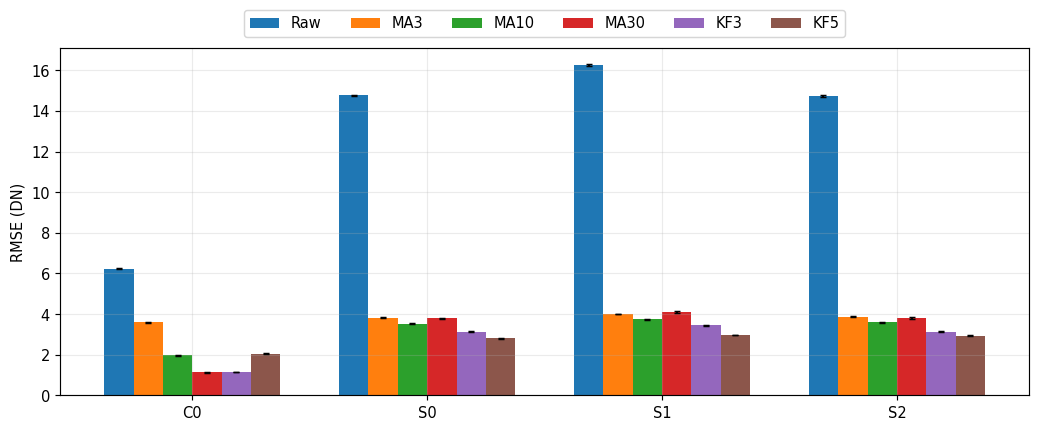

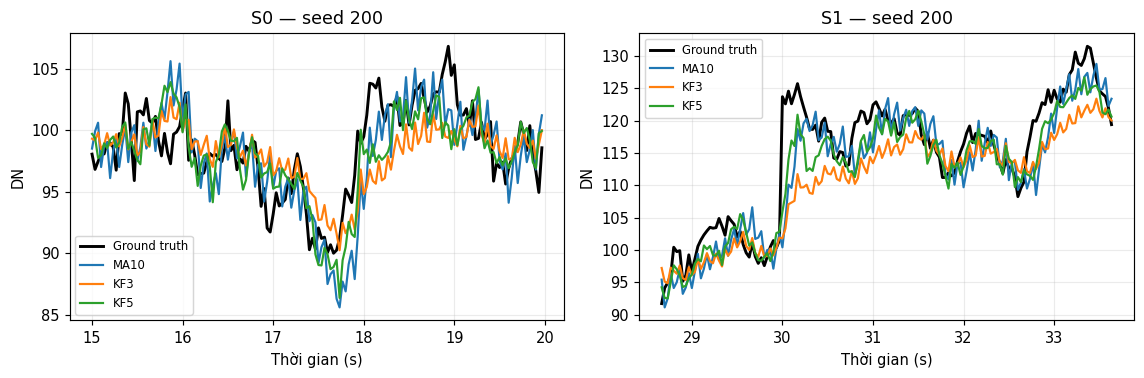

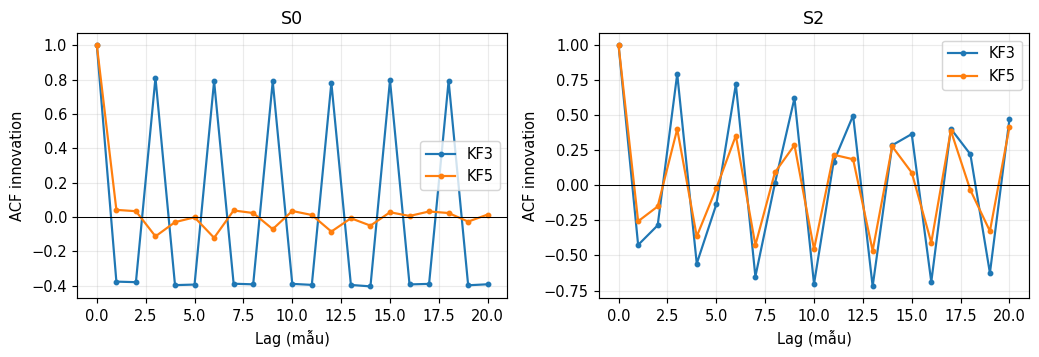

In [14]:
# Kết quả tổng hợp và đáp ứng động: cùng seed, cùng trục thời gian.
methods = ["Raw", "MA3", "MA10", "MA30", "KF3", "KF5"]
scenarios = ["C0", "S0", "S1", "S2"]
fig, ax = plt.subplots(figsize=(10, 4.2))
width = 0.125
for i, method in enumerate(methods):
    sub = mc_table[mc_table.Method == method].set_index("Scenario")
    sub = sub.loc[scenarios]
    ax.bar(np.arange(4)+(i-2.5)*width, sub["RMSE mean"], width,
           yerr=sub["CI95 half-width"], capsize=2, label=method)
ax.set(xticks=np.arange(4), xticklabels=scenarios, ylabel="RMSE (DN)")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.13))
show_figure(fig, "06_rmse.png")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
for axis, scenario, section in ((ax[0], "S0", slice(450, 600)),
                                (ax[1], "S1", slice(860, 1010))):
    x, estimates, _ = examples[scenario]
    time = np.arange(len(x))/config.fs
    axis.plot(time[section], x[section], "k", lw=2, label="Ground truth")
    for method in (f"MA{best_M}", "KF3", "KF5"):
        axis.plot(time[section], estimates[method][section], label=method)
    axis.set(xlabel="Thời gian (s)", ylabel="DN",
             title=f"{scenario} — seed 200")
    axis.legend(fontsize=8)
show_figure(fig, "06_tracking.png")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for axis, scenario in zip(ax, ("S0", "S2")):
    _, _, e = examples[scenario]
    for method in ("KF3", "KF5"):
        axis.plot(np.arange(21), acf(e[method][BURN_IN:,0], 20),
                  marker=".", label=method)
    axis.axhline(0, color="black", lw=0.7)
    axis.set(xlabel="Lag (mẫu)", ylabel="ACF innovation", title=scenario)
    axis.legend()
show_figure(fig, "06_innovation.png")

## 6.3. Phân tích độ nhạy

Mỗi nhóm thay đổi một yếu tố, giữ các yếu tố khác danh nghĩa, 20 seed 600–619. Khảo sát (i) độ sâu điều chế m, (ii) mức trôi tần số lưới cuối bản ghi, (iii) sai lệch R cảm biến và (iv) sai lệch q_x thiết kế. Không cập nhật tham số từ test. Với R scale, chỉ scale phần phương sai cảm biến, không scale công suất Flicker tương đương của KF3. Với q_x scale, nhân q_x chung cho hai KF, không thay đổi các tham số khác. Thêm cảnh tĩnh có Flicker nhằm kiểm tra MA không bị đánh giá bất lợi do ground truth có AR(1).

,Factor,Value,Method,RMSE mean,CI95 half-width,Clipped samples
0,m,0.00,MA10,3.23405,0.05345,0
1,m,0.00,KF3,2.98959,0.05894,0
2,m,0.00,KF5,2.78168,0.04072,0
3,m,0.10,MA10,3.27986,0.06341,0
4,m,0.10,KF3,3.00299,0.05817,0
5,m,0.10,KF5,2.78054,0.04156,0
6,m,0.25,MA10,3.50462,0.05200,0
7,m,0.25,KF3,3.07942,0.05851,0
8,m,0.25,KF5,2.78455,0.04177,0
9,m,0.40,MA10,3.87221,0.05020,0


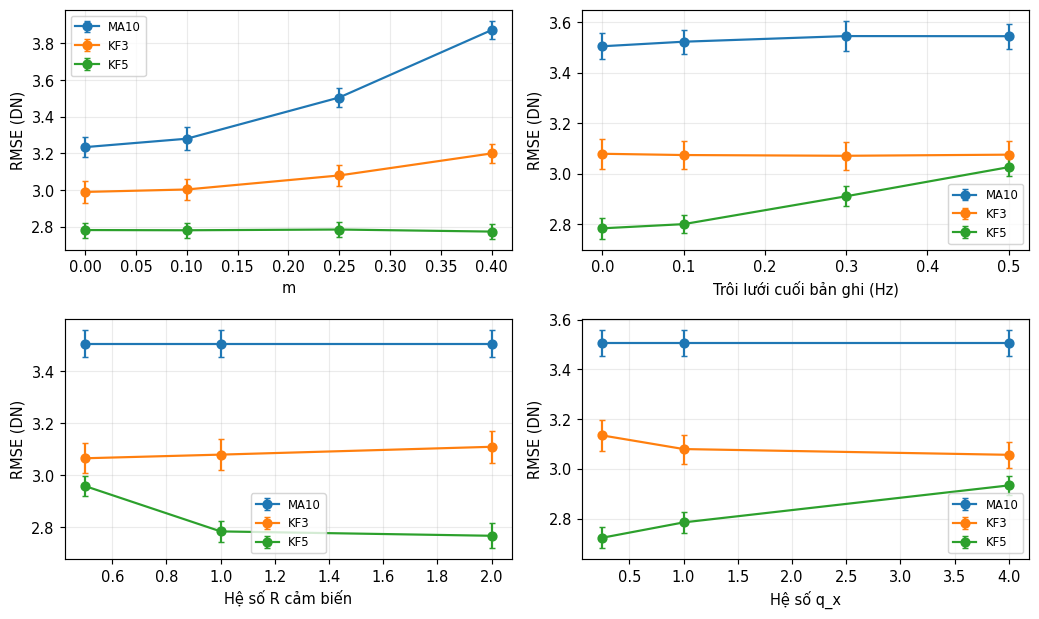

In [15]:
sens_seeds = range(600, 620)
sens_rows = []
experiments = [("m", value) for value in (0.0, 0.1, 0.25, 0.4)]
experiments += [("grid_drift", value) for value in (0.0, 0.1, 0.3, 0.5)]
experiments += [("R_scale", value) for value in (0.5, 1.0, 2.0)]
experiments += [("Qx_scale", value) for value in (0.25, 1.0, 4.0)]
experiments += [("static_with_flicker", 1.0)]
for factor, value in experiments:
    kwargs = {}
    R_scale, Q_scale = 1.0, 1.0
    if factor == "m":
        kwargs["modulation"] = value
    elif factor == "grid_drift":
        kwargs["grid_drift"] = value
    elif factor == "R_scale":
        R_scale = value
    elif factor == "Qx_scale":
        Q_scale = value
    else:
        kwargs["static"] = True
    z, x, clipped = batch_data(sens_seeds, "S0", **kwargs)
    m3 = make_model(cal, config.fs, q_x*Q_scale, R_scale=R_scale)
    m5 = make_model(cal, config.fs, q_x*Q_scale, r, R_scale=R_scale)
    estimates, _ = run_methods(z, m3, m5, diagnostics=False)
    comparison = (f"MA{best_M}", "KF3", "KF5")
    if factor == "static_with_flicker":
        comparison = ("Raw", "MA3", "MA10", "MA30", "KF3", "KF5")
    for method in comparison:
        avg, sd, half = mean_ci(rmse((estimates[method]-x)[:, BURN_IN:]))
        sens_rows.append({"Factor": factor, "Value": value, "Method": method,
                          "RMSE mean": avg, "CI95 half-width": half,
                          "Clipped samples": clipped})
sensitivity = pd.DataFrame(sens_rows)
show_table(sensitivity, "sensitivity.csv")
fig, ax = plt.subplots(2, 2, figsize=(10, 6))
for axis, factor, xlabel in zip(ax.flat,
                               ("m", "grid_drift", "R_scale", "Qx_scale"),
                               ("m", "Trôi lưới cuối bản ghi (Hz)",
                                "Hệ số R cảm biến", "Hệ số q_x")):
    for method in (f"MA{best_M}", "KF3", "KF5"):
        sub = sensitivity[(sensitivity.Factor == factor) &
                          (sensitivity.Method == method)]
        axis.errorbar(sub.Value, sub["RMSE mean"], yerr=sub["CI95 half-width"],
                      marker="o", capsize=2, label=method)
    axis.set(xlabel=xlabel, ylabel="RMSE (DN)")
    axis.legend(fontsize=8)
show_figure(fig, "06_sensitivity.png")

# Chương 7. Kết luận và hướng phát triển

Cell sau tổng hợp trực tiếp kết quả đã chạy, không ghi số liệu cứng. Điểm chọn $q_x,r$ ở biên lưới khảo sát chỉ là tốt nhất trong tập ứng viên, không phải tối ưu toàn cục. Không dùng test để mở rộng hoặc chọn lại lưới tham số. Chênh lệch cặp âm nghĩa là KF5 có RMSE trung bình thấp hơn KF3 trong khảo sát. Không suy ra ưu thế phổ quát; xem cả bước sáng, C0, độ nhạy và innovation. Mô hình tuyến tính dùng R ở điểm làm việc cố định, không mô hình hóa chính xác shot noise heteroscedastic hay Flicker nhân. Dữ liệu là mô phỏng theo camera tham chiếu, OB lý tưởng, thông số môi trường chưa đo, không có kiểm chứng trên camera thật. Nếu sai lệch tần số làm tăng RMSE, thích nghi tần số là hướng mở rộng cần nghiên cứu riêng; Notebook này không triển khai RLS/RIV.

## Xuất kết quả

Notebook chứa đầy đủ đầu ra. PNG và CSV được sinh lại khi chạy, dùng cho báo cáo và slide; không cần dữ liệu ngoài. Các file phiên bản và cấu hình giúp đối chiếu kết quả. Không tự upload hoặc ghi đè GitHub từ Notebook.

In [16]:
pivot = mc_table.pivot(index="Scenario", columns="Method", values="RMSE mean")
print("RMSE trung bình (DN) sau burn-in; thấp hơn là tốt hơn:")
display(pivot.round(3))
for row in paired_table.to_dict("records"):
    delta, half = row["KF5-KF3 RMSE"], row["CI95 half-width"]
    print(f"{row['Scenario']}: KF5 − KF3 = {delta:+.3f} ± {half:.3f} DN")
print("Phương pháp có RMSE nhỏ nhất theo từng kịch bản (chỉ mô phỏng):")
print(pivot.idxmin(axis=1).to_string())
# Các nhận xét được tính từ bảng kết quả, nhất quán với lần chạy hiện tại.
nominal = pivot.loc["S0"]
step = step_table.set_index("Method")
inn = innov_table.set_index(["Scenario", "Method"])
reduction = 100*(1-nominal.KF5/nominal.KF3)
static_best = pivot.loc["C0"].idxmin()
static_flicker = sensitivity[sensitivity.Factor == "static_with_flicker"]
static_flicker_best = static_flicker.loc[static_flicker["RMSE mean"].idxmin()]
display(Markdown(f"""
**Nhận xét từ lần chạy này**

- S0: KF5 giảm RMSE trung bình {reduction:.2f}% so với KF3; xem CI cặp
  ở trên. MA được chọn trên validation là MA{best_M}.
- C0: RMSE trung bình nhỏ nhất thuộc về {static_best}. Trong khảo sát
  cảnh tĩnh có Flicker, phương pháp có RMSE trung bình thấp nhất là
  {static_flicker_best.Method}. Không có phương pháp thắng mọi điều kiện.
- S1: RMSE 3 giây sau bước của KF5 = {step.loc['KF5','Step RMSE']:.3f} DN,
  MA3 = {step.loc['MA3','Step RMSE']:.3f} DN; sai số đỉnh trung bình của
  KF5 = {step.loc['KF5','Step peak']:.3f} DN, MA3 =
  {step.loc['MA3','Step peak']:.3f} DN. Bám bước và RMSE toàn đoạn là
  hai tiêu chí khác nhau.
- S0: max |ACF| innovation giảm từ {inn.loc[('S0','KF3'),'Max ACF']:.3f}
  xuống {inn.loc[('S0','KF5'),'Max ACF']:.3f}; tỷ lệ không bác bỏ
  Ljung–Box của KF5 là {100*inn.loc[('S0','KF5'),'nonreject']:.0f}%.
  Giảm tương quan không đồng nghĩa innovation trắng.
- S2: KF5 có RMSE {pivot.loc['S2','KF5']:.3f} DN so với
  {pivot.loc['S0','KF5']:.3f} DN ở S0, cho thấy cần khảo sát thích nghi
  nếu phạm vi trôi tần số hoặc yêu cầu chất lượng tăng lên. Chưa có
  thí nghiệm thích nghi để kết luận định lượng về lợi ích của RLS/RIV.
"""))
metadata = {"config": asdict(config), "versions": versions,
            "calibration_seed": 11, "calibration": cal, "q_x": q_x, "r": r,
            "best_ma": int(best_M), "burn_in": BURN_IN,
            "step_window": [STEP_WINDOW.start, STEP_WINDOW.stop],
            "validation_seeds": [100,109], "test_seeds": [200,299],
            "sensitivity_seeds": [600,619]}
(RESULT_DIR / "configuration.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)
# Gói đầu ra riêng để tải về từ thanh Files của Colab.
with ZipFile("EE6423_outputs.zip", "w", ZIP_DEFLATED) as archive:
    for folder in (FIG_DIR, RESULT_DIR):
        for path in sorted(folder.iterdir()):
            if path.is_file():
                archive.write(path, arcname=str(path))
print(f"Đã tạo {len(list(FIG_DIR.glob('*.png')))} hình PNG và "
      f"{len(list(RESULT_DIR.iterdir()))} file kết quả.")

RMSE trung bình (DN) sau burn-in; thấp hơn là tốt hơn:


Method,KF3,KF5,MA10,MA3,MA30,Raw
Scenario,,,,,,
C0,1.139,2.046,1.968,3.593,1.132,6.219
S0,3.126,2.797,3.529,3.819,3.788,14.770
S1,3.448,2.964,3.736,4.001,4.098,16.250
S2,3.125,2.932,3.588,3.875,3.813,14.734


C0: KF5 − KF3 = +0.907 ± 0.006 DN
S0: KF5 − KF3 = -0.329 ± 0.017 DN
S1: KF5 − KF3 = -0.484 ± 0.017 DN
S2: KF5 − KF3 = -0.193 ± 0.016 DN
Phương pháp có RMSE nhỏ nhất theo từng kịch bản (chỉ mô phỏng):
Scenario
C0    MA30
S0     KF5
S1     KF5
S2     KF5



**Nhận xét từ lần chạy này**

- S0: KF5 giảm RMSE trung bình 10.53% so với KF3; xem CI cặp
  ở trên. MA được chọn trên validation là MA10.
- C0: RMSE trung bình nhỏ nhất thuộc về MA30. Trong khảo sát
  cảnh tĩnh có Flicker, phương pháp có RMSE trung bình thấp nhất là
  MA30. Không có phương pháp thắng mọi điều kiện.
- S1: RMSE 3 giây sau bước của KF5 = 4.195 DN,
  MA3 = 4.409 DN; sai số đỉnh trung bình của
  KF5 = 16.269 DN, MA3 =
  14.335 DN. Bám bước và RMSE toàn đoạn là
  hai tiêu chí khác nhau.
- S0: max |ACF| innovation giảm từ 0.817
  xuống 0.133; tỷ lệ không bác bỏ
  Ljung–Box của KF5 là 0%.
  Giảm tương quan không đồng nghĩa innovation trắng.
- S2: KF5 có RMSE 2.932 DN so với
  2.797 DN ở S0, cho thấy cần khảo sát thích nghi
  nếu phạm vi trôi tần số hoặc yêu cầu chất lượng tăng lên. Chưa có
  thí nghiệm thích nghi để kết luận định lượng về lợi ích của RLS/RIV.


Đã tạo 10 hình PNG và 16 file kết quả.
